# FoodShock Indonesia
**Multi-Horizon Food Price & Shock Forecasting**

SDG 2.c · Machine Learning Solution Challenge 2026

Alur notebook identik dengan Streamlit. Model harga dan shock menggunakan shared functions dari `src.forecast` dan `src.train`.

## 1. Overview
Lonjakan harga pangan mengurangi keterjangkauan pangan. FoodShock memprediksi harga pangan pada bulan target dan risiko kenaikan minimal 5% terhadap bulan sebelumnya. Data WFP Indonesia 2015–2025 digunakan untuk mendukung pemantauan pasar (SDG 2.c), bukan menggantikan verifikasi harga.

Konfigurasi `REBUILD=False` membuka hasil penelitian tersimpan. Ubah ke `True` untuk melatih ulang seluruh penelitian dari raw regional.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0,str(ROOT))
os.environ.setdefault('OMP_NUM_THREADS','2')
os.environ.setdefault('OPENBLAS_NUM_THREADS','2')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.forecast import load, eligible, forecast_path, FEATURES, KEY
REBUILD = False
if REBUILD:
    from src.train import main
    main()
d, bundle = load()
print('Monthly records:',len(d),'| Markets:',d.market_id.nunique(),'| Products:',d.commodity_id.nunique())
print('Selected price model:',bundle['selected'],'| Risk model:',bundle['risk_selected'])
d[['date','province','market','commodity','unit','price']].head()

Monthly records: 327163 | Markets: 223 | Products: 29
Selected price model: Histogram Gradient Boosting | Risk model: Histogram Gradient Boosting


,date,province,market,commodity,unit,price
0,2015-01-01,National / unspecified,National Average,Rice,KG,12444.0
1,2015-02-01,National / unspecified,National Average,Rice,KG,12802.0
2,2015-03-01,National / unspecified,National Average,Rice,KG,13089.0
3,2015-04-01,National / unspecified,National Average,Rice,KG,12458.0
4,2015-05-01,National / unspecified,National Average,Rice,KG,12348.0


## 2. Exploratory Data Analysis
Cakupan historis tidak merata. Harga tidak dibandingkan antarproduk atau unit yang berbeda. Frekuensi shock dihitung hanya dari observasi bulanan berurutan.

,file,indonesia_rows
0,wfp_food_prices_global_2015.csv,120
1,wfp_food_prices_global_2016.csv,22768
2,wfp_food_prices_global_2017.csv,4317
3,wfp_food_prices_global_2018.csv,120
4,wfp_food_prices_global_2019.csv,120
5,wfp_food_prices_global_2020.csv,62699
6,wfp_food_prices_global_2021.csv,65352
7,wfp_food_prices_global_2022.csv,65575
8,wfp_food_prices_global_2023.csv,63486
9,wfp_food_prices_global_2024.csv,22414


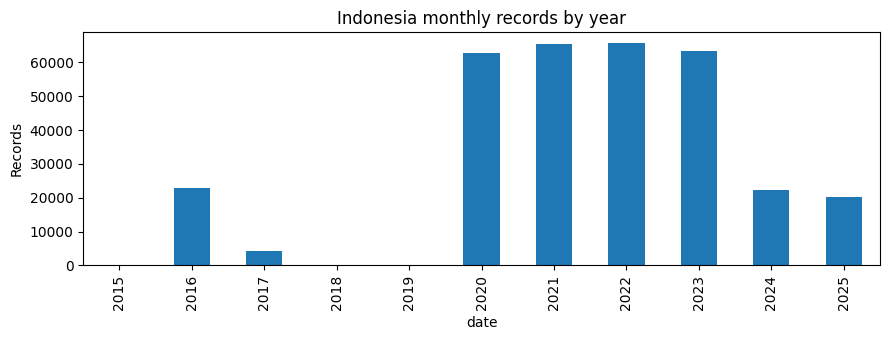

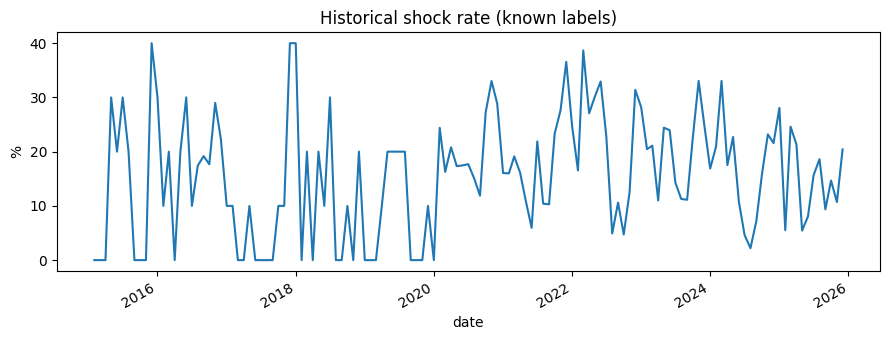

,observations
commodity,
Eggs,15578
Oil (vegetable),15558
Garlic (medium),15524
"Onions (shallot, medium)",15524
Sugar (local),15517
Rice (medium quality),15331
Meat (chicken),15261
"Meat (beef, first quality)",14225
Rice,11702


In [2]:
audit=pd.read_csv(ROOT/'data/raw/source_manifest.csv')
display(audit[['file','indonesia_rows']])
fig, ax=plt.subplots(figsize=(9,3.5));d.groupby(d.date.dt.year).size().plot.bar(ax=ax,title='Indonesia monthly records by year');ax.set_ylabel('Records');plt.tight_layout();plt.show()
known=d[d.mom1.notna()].copy();known['shock']=(known.mom1>=np.log(1.05)-1e-10).astype(int)
fig,ax=plt.subplots(figsize=(9,3.5));known.groupby('date').shock.mean().mul(100).plot(ax=ax,title='Historical shock rate (known labels)');ax.set_ylabel('%');plt.tight_layout();plt.show()
d.groupby('commodity').size().sort_values(ascending=False).head(10).to_frame('observations')

## 3. Preprocessing
Filter harga pangan retail IDR, agregasi bulanan, exact-calendar lag, volatilitas, tren, seasonality, horizon, dan missing flags. Harga hilang tidak diinterpolasi. Empat bulan berurutan diperlukan untuk origin eligible. Label shock memakai harga aktual bulan target dibanding bulan sebelumnya. Training pairs tidak melampaui cutoff label. Source lengkap: `src/forecast.py`.

In [3]:
assert not d.duplicated(KEY+['date']).any()
assert (d.price>0).all()
print('Eligible origins:',len(eligible(d)))
print('Features:',FEATURES)
display(pd.read_csv(ROOT/'results/split_audit.csv'))
d[['date','market','commodity','price','mom1','mom3','mom6','mom12','vol3','trend']].head(15)

Eligible origins: 287879
Features: ['mom1', 'mom3', 'mom6', 'mom12', 'vol3', 'trend', 'history', 'season_sin', 'season_cos', 'origin_sin', 'origin_cos', 'h', 'h2', 'trend_h', 'season_delta', 'mom6_missing', 'mom12_missing']


,origin,training_pairs,evaluation_pairs
0,2020-12-01,17056,124216
1,2021-12-01,49786,65543
2,2022-12-01,85422,104875
3,2025-12-01,129646,0


,date,market,commodity,price,mom1,mom3,mom6,mom12,vol3,trend
0,2015-01-01,National Average,Rice,12444.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-02-01,National Average,Rice,12802.0,0.028363,NaN,NaN,NaN,NaN,NaN
2,2015-03-01,National Average,Rice,13089.0,0.022171,NaN,NaN,NaN,NaN,NaN
3,2015-04-01,National Average,Rice,12458.0,-0.049409,0.001124,NaN,NaN,0.035293,0.000375
4,2015-05-01,National Average,Rice,12348.0,-0.008869,-0.036107,NaN,NaN,0.029308,-0.012036
5,2015-06-01,National Average,Rice,12425.0,0.006216,-0.052062,NaN,NaN,0.023488,-0.017354
6,2015-07-01,National Average,Rice,12509.0,0.006738,0.004085,0.005210,NaN,0.007237,0.000868
7,2015-08-01,National Average,Rice,12709.0,0.015862,0.028816,-0.007291,NaN,0.004429,-0.001215
8,2015-09-01,National Average,Rice,12968.0,0.020174,0.042774,-0.009287,NaN,0.005601,-0.001548
9,2015-10-01,National Average,Rice,13067.0,0.007605,0.043642,0.047727,NaN,0.005215,0.007954


## 4. Training & Testing
Model harga: Ridge dan HGB, dibandingkan Persistence dan Seasonal Naive. Model risk: Logistic Regression dan HGB. Validation A (origin Des 2020) dan B (Des 2021) untuk pemilihan model/threshold. Test retrospektif origin Des 2022, target 2023–2025. Deployment refit hingga 2025. Threshold classifier dibatasi FPR validasi ≤10%, tidak menjamin FPR test atau masa depan. Semua angka dibaca dari hasil training aktual.

,phase,model,horizon,n,MAPE,RMSLE
0,2020-12-01,Persistence,All,124216,15.561924,0.239518
6,2020-12-01,Seasonal Naive,All,124216,17.537793,0.313719
12,2020-12-01,Ridge,All,124216,23.763593,0.310837
18,2020-12-01,Histogram Gradient Boosting,All,124216,21.411380,0.276276
24,2021-12-01,Persistence,All,65543,15.145861,0.241183
29,2021-12-01,Seasonal Naive,All,65543,16.983539,0.306400
34,2021-12-01,Ridge,All,65543,14.132952,0.232150
39,2021-12-01,Histogram Gradient Boosting,All,65543,16.714785,0.271910
44,Test 2023–2025,Persistence,All,104875,13.863737,0.226267
51,Test 2023–2025,Seasonal Naive,All,104875,17.956474,0.258268


,phase,model,horizon,n,MAPE,RMSLE
65,Test 2023–2025,Histogram Gradient Boosting,All,104875,16.863148,0.231945
66,Test 2023–2025,Histogram Gradient Boosting,1,5453,5.883458,0.094435
67,Test 2023–2025,Histogram Gradient Boosting,3,5427,10.530725,0.152811
68,Test 2023–2025,Histogram Gradient Boosting,6,5427,31.737855,0.377790
69,Test 2023–2025,Histogram Gradient Boosting,12,5127,14.165387,0.212201
70,Test 2023–2025,Histogram Gradient Boosting,24,1616,13.492727,0.194562
71,Test 2023–2025,Histogram Gradient Boosting,36,1638,12.908750,0.181262


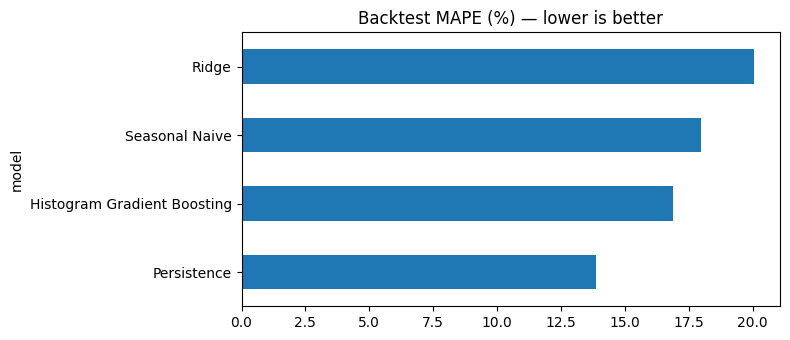

,phase,model,horizon,n,threshold,AP,AUC,precision,recall,F1,FPR,TP,FP,FN,TN,prevalence
0,Validation pooled,Logistic Regression,All,189707,0.257257,0.256028,0.565153,0.319879,0.183816,0.233470,0.099936,7101,15098,31530,135978,0.203635
1,Validation pooled,Histogram Gradient Boosting,All,189707,0.445375,0.350728,0.707070,0.411120,0.272760,0.327944,0.099903,10537,15093,28094,135983,0.203635
2,Test 2023–2025,Logistic Regression,All,102621,0.257257,0.311412,0.680771,0.384597,0.335608,0.358437,0.123559,6442,10308,12753,73118,0.187047
9,Test 2023–2025,Histogram Gradient Boosting,All,102621,0.445375,0.324962,0.693191,0.405677,0.252409,0.311195,0.085081,4845,7098,14350,76328,0.187047


,Predicted non-shock,Predicted shock
Actual non-shock,76328,7098
Actual shock,14350,4845


,model,horizon,n,coverage,log_error_q10,log_error_q90,calibration_note
0,Ridge,1–3,16283,0.817110,-0.207360,0.180579,validation quantiles
1,Ridge,4–6,16283,0.746300,-0.213064,0.321644,validation quantiles
2,Ridge,7–12,30764,0.804187,-0.272467,0.284864,validation quantiles
3,Ridge,13–24,22114,0.949127,-0.416892,0.440445,validation quantiles
4,Ridge,25–36,19431,0.976996,-0.416892,0.440445,13–24 reused
5,Histogram Gradient Boosting,1–3,16283,0.903089,-0.347914,0.120284,validation quantiles
6,Histogram Gradient Boosting,4–6,16283,0.807898,-0.329641,0.248458,validation quantiles
7,Histogram Gradient Boosting,7–12,30764,0.825770,-0.380017,0.269571,validation quantiles
8,Histogram Gradient Boosting,13–24,22114,0.860450,-0.360981,0.273746,validation quantiles
9,Histogram Gradient Boosting,25–36,19431,0.900160,-0.360981,0.273746,13–24 reused


In [4]:
metrics=pd.read_csv(ROOT/'results/forecast_metrics.csv');risk=pd.read_csv(ROOT/'results/shock_metrics.csv')
MODEL=bundle['selected']  # 'Ridge' atau 'Histogram Gradient Boosting'
test=metrics[metrics.phase.str.startswith('Test')]
display(metrics[metrics.horizon.astype(str)=='All'])
display(test[test.model.eq(MODEL)])
fig,ax=plt.subplots(figsize=(8,3.5));test[test.horizon.astype(str)=='All'].set_index('model').MAPE.sort_values().plot.barh(ax=ax,title='Backtest MAPE (%) — lower is better');plt.tight_layout();plt.show()
display(risk[risk.horizon.astype(str)=='All'])
q=risk[risk.phase.str.startswith('Test') & risk.model.eq(bundle['risk_selected']) & risk.horizon.astype(str).eq('All')].iloc[0]
display(pd.DataFrame([[q.TN,q.FP],[q.FN,q.TP]],index=['Actual non-shock','Actual shock'],columns=['Predicted non-shock','Predicted shock']).astype(int))
display(pd.read_csv(ROOT/'results/interval_coverage.csv'))

**Interpretasi:** Persistence memiliki MAPE agregat paling rendah, sedangkan HGB lebih baik pada horizon panjang 24 dan 36 bulan. Pemilihan HGB classifier didasarkan pada recall dengan batas FPR validasi; precision dan recall test tetap terbatas. Evaluasi ini retrospektif, bukan jaminan performa pada 2028.

## 5. Prediction
Masukkan target tanggal, bukan tanggal acuan. Data bulanan: semua tanggal dalam bulan sama menghasilkan prediksi sama. `SERIES_ID` dipilih dari daftar pasar–produk dengan origin layak tahun 2025. Hasil menggunakan engine yang sama dengan Streamlit. Horizon di atas 36 bulan ditandai ekstrapolasi (tanpa risk score ML).

,series,province,market,commodity,unit,date
6675,111,ACEH,Pasar Inpres,Eggs,KG,2025-12-01
7629,128,ACEH,Pasar Inpres,Garlic (medium),KG,2025-12-01
7135,118,ACEH,Pasar Inpres,"Meat (beef, first quality)",KG,2025-12-01
6751,112,ACEH,Pasar Inpres,Meat (chicken),KG,2025-12-01
6827,113,ACEH,Pasar Inpres,Oil (vegetable),KG,2025-12-01
7975,134,ACEH,Pasar Inpres,"Onions (shallot, medium)",KG,2025-12-01
7705,129,ACEH,Pasar Inpres,Rice (medium quality),KG,2025-12-01
7781,130,ACEH,Pasar Inpres,Sugar (local),KG,2025-12-01
8227,138,ACEH,Pasar Kota Lhokseumawe,Eggs,KG,2025-12-01
9184,155,ACEH,Pasar Kota Lhokseumawe,Garlic (medium),KG,2025-12-01


Pasar Mundu | Rice (medium quality) | KG | origin 2025-12
Target: 2028-01 | Horizon: 25 bulan
Predicted price: Rp17,184 | Change: +0.40% | Risk score: 0.061
Classification: NON-SHOCK


,lower,upper,date,horizon,price,change,risk_score,shock,price_implied_shock,extrapolation
19,11594.653030,21873.393139,2027-08-01,20,16635.264297,0.001956,0.040376,False,False,False
20,11687.632224,22048.799031,2027-09-01,21,16768.664879,0.008019,0.062717,False,False,False
21,11738.131435,22144.066143,2027-10-01,22,16841.117907,0.004321,0.062531,False,False,False
22,11832.523797,22322.137986,2027-11-01,23,16976.546012,0.008042,0.062651,False,False,False
23,11929.627940,22505.325624,2027-12-01,24,17115.864807,0.008207,0.059943,False,False,False
24,11977.387749,22595.424834,2028-01-01,25,17184.387517,0.004003,0.060521,False,False,False


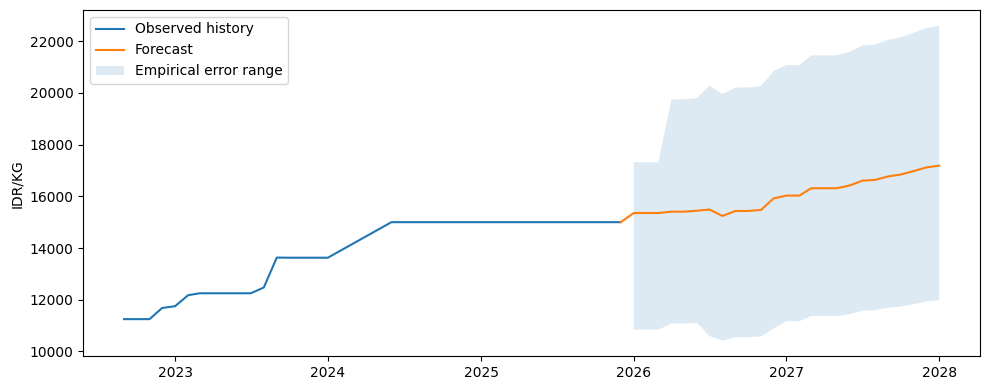

In [5]:
latest=eligible(d).sort_values('date').groupby('series',as_index=False).tail(1)
choices=latest[latest.date.dt.year.eq(2025)][['series','province','market','commodity','unit','date']].sort_values(['province','market','commodity'])
display(choices.head(15))
TARGET_DATE='2028-01-31'
SERIES_ID=868  # Pasar Mundu, Rice (medium quality), KG
ALGORITHM=None  # None = selected price model; atau 'Ridge'
origin,path=forecast_path(d,SERIES_ID,TARGET_DATE,bundle,ALGORITHM)
print(f'{origin.market} | {origin.commodity} | {origin.unit} | origin {origin.date:%Y-%m}')
r=path.iloc[-1]
print('Target:',r.date.strftime('%Y-%m'),'| Horizon:',r.horizon,'bulan')
print(f'Predicted price: Rp{r.price:,.0f} | Change: {r.change:+.2%} | Risk score: {r.risk_score:.3f}')
print('Classification:', 'Extrapolation (price-implied shock only)' if r.extrapolation else ('SHOCK' if r.shock else 'NON-SHOCK'))
display(path.tail(6))
hist=d[d.series.eq(SERIES_ID)&d.date.le(origin.date)].sort_values('date').tail(36)
fig,ax=plt.subplots(figsize=(10,4));ax.plot(hist.date,hist.price,label='Observed history');ax.plot(pd.concat([pd.Series([origin.date]),path.date],ignore_index=True),np.r_[origin.price,path.price],label='Forecast');ax.fill_between(path.date,path.lower,path.upper,alpha=.15,label='Empirical error range');ax.set_ylabel(f'IDR/{origin.unit}');ax.legend();plt.tight_layout();plt.show()

### Limitations
Harga dan risk score masa depan bersifat kondisional. Tidak ada data pasokan, cuaca, atau kebijakan setelah 2025. Rentang empiris bukan jaminan cakupan; untuk horizon 25–36 menggunakan rentang 13–24. Untuk target lebih jauh dari 36 bulan, hanya ekstrapolasi musiman dengan tren teredam yang disediakan. Lihat README untuk sumber data, instruksi reproduksi, dan seluruh keterbatasan.

**References:** [Kaggle WFP dataset](https://www.kaggle.com/datasets/abhishekgupta56447/global-food-prices-database-wfp); [UN SDG 2](https://sdgs.un.org/goals/goal2).